# 7 — Evaluación de modelos: sesgo, varianza y validación cruzada

📓 [Notebook de clase](../raw/7_evaluacion_modelos.ipynb) · ✏️ [Ejercicios](../exercises/7_evaluacion_modelos.ipynb) · 📕 *ESL* cap. 7 como referencia principal · 📘 Bishop §1.5.5 y §3.2

> **TL;DR**
>
> - Evaluar tiene dos objetivos distintos: **elegir** entre modelos (*model selection*, que incluye elegir hiperparámetros) y **medir** el error del elegido (*model assessment*). Si usás los mismos datos para las dos cosas, el número que reportás es optimista: probaste muchas opciones y te quedaste con la que tuvo suerte.
> - Con pérdida cuadrática, el mejor predictor posible es $f(x) = E(Y \mid X = x)$. Lo que sobra, $\mathrm{Var}(Y \mid X = x)$, es el **error irreducible**: ningún modelo lo baja.
> - Si promediás sobre todos los conjuntos de entrenamiento posibles, el error de test se parte en **sesgo² + varianza + error irreducible**. Subir la complejidad baja el sesgo y sube la varianza. Para OLS la varianza promedio es $\frac{p}{N}\sigma_\varepsilon^2$; Ridge la achica a cambio de sesgo.
> - Hay varios "errores" (§5): el de entrenamiento, el de *tu* modelo en datos nuevos y el promedio sobre todos los conjuntos de entrenamiento posibles. El de entrenamiento es optimista: para un ajuste lineal se queda corto, en promedio, en $2\,df\,\sigma_\varepsilon^2/N$, donde $df$ es la cantidad efectiva de parámetros.
> - La **validación cruzada K-fold** evalúa cada muestra con un modelo que no la vio y promedia sobre las $N$ muestras. Sirve para elegir $\alpha$ y estima bien $Err$, pero **no** $Err_\tau$. $K = 5$ o $10$ es el compromiso habitual.

## 🗺️ Mapa de la clase

Cuando el texto dice "celda N", habla de la **notebook de clase** (📓), no de esta.

| Bloque de la clase | Celdas | Dónde lo explico |
|--------------------|--------|------------------|
| Evaluación de modelos › Bibliografía | 0 | §1 (los papers) |
| Evaluación de modelos | 1–15 | §1 |
| Pérdida y error › Regresión | 16 | §2 |
| Pérdida y error › Teoría de la decisión | 17–18 | §2 |
| Pérdida y error (versión Bishop) | 19–20 | §2 |
| Descomposición sesgo-varianza | 21–33 | §3 |
| Errores (primera vez) | 34 | §5 |
| Descomposición sesgo-varianza: OLS y Ridge | 35–42 | §4 |
| Errores | 43–46 | §5 |
| Para pensar: ¿cuál error queremos estimar y por qué? | 47 | §5 |
| Errores › Estrategias de estimación | 48 | §5 |
| Validación cruzada › K-Fold | 49–52 | §6 |
| Validación cruzada | 53 | §6 |

In [1]:
# Setup
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "figure.dpi": 110,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "legend.frameon": False,
})
np.set_printoptions(precision=2, suppress=True)
colores = sns.color_palette("colorblind")

## 0. Notación y el ejemplo que nos acompaña

📕 ESL §7.2

La clase usa varios símbolos nuevos, y en el medio cambia de convención. Esta es la tabla para no perderse:

| Símbolo | Cómo leerlo | Qué es |
|---|---|---|
| $\tau = \{(x_i, y_i)\}_{i=1}^N$ | "tau" | El **conjunto de entrenamiento**: $N$ pares sacados al azar de $P(X, Y)$. ESL lo escribe $\mathcal{T}$. |
| $f(x) = E(Y \mid X = x)$ | "efe de equis" | La **función de regresión** verdadera. Nunca la conocemos. |
| $\hat f(x)$, o $f(x;\tau)$ | "efe sombrero" | El modelo **ajustado**. $f(x;\tau)$ dice lo mismo, pero deja explícito que depende de qué $\tau$ te tocó. |
| $E_\tau[\cdot]$ | "esperanza sobre tau" | El promedio sobre **todos los conjuntos de entrenamiento** de tamaño $N$ que podrían haberte tocado. |
| $E_Y[\cdot \mid X = x]$ | "esperanza sobre Y dado x" | El promedio sobre $Y$ con el $x$ fijo. El subíndice dice *sobre qué* se promedia. |
| $\varepsilon$, $\sigma_\varepsilon^2$ | "épsilon", "sigma cuadrado" | El ruido, en el modelo $Y = f(X) + \varepsilon$, y su varianza. |
| $\alpha$ | "alfa" | El parámetro de Ridge. En la clase 4 y en ESL cap. 3 se llama $\lambda$; en ESL cap. 7, igual que acá, es $\alpha$. |
| $df$ | "grados de libertad" | La complejidad efectiva del modelo (§4). |

**El salto de notación.** En las celdas 19–25 la clase sigue a Bishop: ahí $f(x)$ es *cualquier* predictor y la verdad se escribe $E_Y[Y \mid X = x]$. Desde la celda 35 vuelve a ESL: $f$ es la verdad y $\hat f$ el modelo. Es la misma cuenta con otros nombres. Acá uso la de ESL de punta a punta.

### El ejemplo de toda la clase

Para ver sesgo, varianza y los distintos errores hace falta algo que en la vida real no tenés: **conocer $f$** y poder **sacar todos los $\tau$ que quieras**. Así que armamos un mundo de juguete, el mismo de la celda 28 de la clase:

- $p = 50$ variables con distribución normal estándar, de las cuales **solo 5** influyen en $Y$.
- $f(x) = x^T\beta$ es lineal, y el ruido tiene desvío $\sigma_\varepsilon = 20$.
- Cada $\tau$ tiene $N = 70$ datos: muy pocos para 50 variables, que es justo lo que hace interesante el problema.
- El modelo es Ridge, ajustado con la fórmula por SVD de la clase 4.

Lo usamos en todas las secciones.

In [2]:
from sklearn.datasets import make_regression

p, N, sigma = 50, 70, 20.0           # variables, datos por tau, desvío del ruido
_, _, beta_true = make_regression(n_samples=1, n_features=p, n_informative=5,
                                  coef=True, random_state=0)
rng = np.random.default_rng(42)

def muestrear(n):
    # Un conjunto de n pares (x, y) sacados de P(X, Y)
    X = rng.standard_normal((n, p))
    return X, X @ beta_true + sigma * rng.standard_normal(n)

def ridge(X, y, alphas):
    # Ridge por SVD (clase 4): una columna de coeficientes por alpha; el intercepto no se penaliza
    mx, my = X.mean(axis=0), y.mean()
    U, d, Vt = np.linalg.svd(X - mx, full_matrices=False)
    B = Vt.T @ ((d / (d**2 + alphas[:, None])) * (U.T @ (y - my))).T
    return B, my - mx @ B, d

X_test, y_test = muestrear(1000)     # "datos nuevos": aproximan la esperanza sobre (X0, Y0)
f_test = X_test @ beta_true          # la f verdadera en esos puntos, sin ruido
alphas = np.logspace(-2, 5, 36)
print("coeficientes no nulos de la f verdadera:", beta_true[beta_true != 0])

coeficientes no nulos de la f verdadera: [19.66 11.04 65.63 13.82 15.9 ]


## 1. Elegir y medir: por qué la receta no es arbitraria

📓 celdas 0–15 · 📕 ESL §7.1–7.2

### La idea en criollo

Mil personas responden un multiple choice de 10 preguntas **tirando una moneda**. Alguna va a sacar 9 o 10, por pura suerte. Si la contratás como "la mejor", en el próximo examen va a sacar lo mismo que todos: 5.

Elegir el mejor de muchos modelos con un número ruidoso es lo mismo. El ganador ganó en parte porque es bueno y en parte porque **el ruido lo favoreció**. Su número está inflado, y una medición nueva lo devuelve a su lugar.

> **Dónde se rompe la analogía.** En el examen todos eran igual de malos. Entre modelos sí hay diferencias reales. El efecto es el mismo, pero su tamaño depende de cuánto pesa el ruido de medición frente a esas diferencias. Si un modelo es muchísimo mejor que el resto, la suerte casi no cambia quién gana.

### Formalizándolo

La celda 1 pone los dos objetivos de ESL §7.1:

1. **Selección de modelos.** Comparar candidatos y quedarse con uno.
2. **Evaluación** (*assessment*). Estimar el error del elegido en datos nuevos.

La celda 1 pregunta *por qué la optimización de hiperparámetros es selección de modelos*. Cada valor de $\alpha$ define un modelo distinto, $\hat f(x, \alpha)$. Elegir $\alpha$ es elegir un modelo entre infinitos, así que cae en el objetivo 1 y sufre el mismo problema de "ganó por suerte".

**La receta** de la celda 2 separa los dos objetivos con datos distintos. El conjunto de **test** se guarda desde el principio y se usa una única vez, al final. Toda la selección pasa dentro del **entrenamiento**, con validación cruzada. ESL §7.2 lo dice con una imagen: el test se guarda "en una bóveda". Si lo usás varias veces para elegir, su error **subestima** el error real del modelo final. Con datos de sobra, ESL sugiere un reparto típico de 50 % entrenamiento, 25 % validación y 25 % test. El resto del capítulo es para cuando no alcanzan los datos para tres partes.

**El experimento de las celdas 5–15.** Es el único ejemplo que queda afuera del mundo de juguete: no hay modelo, solo ruido de medición. Tres hiperparámetros con 10 valores cada uno dan $10^3 = 1000$ combinaciones. La clase supone que **todas rinden igual**: accuracy real $0.8$. Cada fold de una CV de 5 folds la mide con un ruido de desvío $0.025$. Hay tres cuentas que se pueden hacer antes de simular:

- El promedio de 5 folds tiene desvío $0.025/\sqrt{5} \approx 0.011$. El máximo de 1000 normales cae, aproximadamente, unos 3 desvíos por encima de la media. El "mejor" modelo va a mostrar cerca de $0.8 + 3 \cdot 0.011 \approx 0.834$, **sin ser mejor en nada**.
- La probabilidad de que un modelo dé por encima de $0.8$ en los 5 folds es $(1/2)^5 = 1/32$, porque cada fold queda arriba o abajo con probabilidad $1/2$ y los folds son independientes. Esperás $1000/32 \approx 31$ modelos "consistentemente mejores" que son puro ruido.
- La celda 12 pregunta si una medición nueva "corrige" el resultado. Sí: la medición nueva es independiente de la selección, así que vuelve a dar alrededor de $0.8$. Es la **regresión a la media**.

Mejor promedio de CV: 0.839 (el real es 0.8)
Con los 5 folds por encima de 0.8: 32 configuraciones (esperado ≈ 31)
Esas mismas, en la medición nueva: 0.796


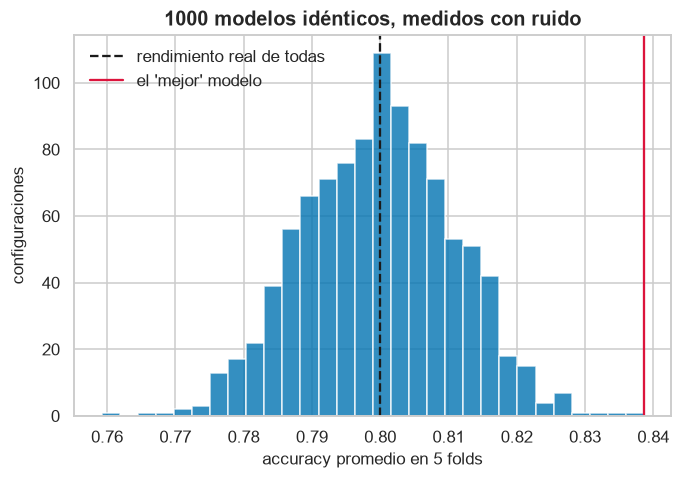

In [3]:
gen = np.random.default_rng(0)
real, ruido, K, n_conf = 0.8, 0.025, 5, 1000
folds = gen.normal(real, ruido, size=(n_conf, K))   # lo que mide cada fold, para cada configuración
media_cv = folds.mean(axis=1)
todos_arriba = (folds > real).all(axis=1)
nueva = gen.normal(real, ruido, size=n_conf)         # una medición nueva, independiente de la elección

print(f"Mejor promedio de CV: {media_cv.max():.3f} (el real es {real})")
print(f"Con los 5 folds por encima de {real}: {todos_arriba.sum()} configuraciones (esperado ≈ {n_conf / 2**K:.0f})")
print(f"Esas mismas, en la medición nueva: {nueva[todos_arriba].mean():.3f}")

fig, ax = plt.subplots()
ax.hist(media_cv, bins=30, color=colores[0], alpha=0.8)
ax.axvline(real, color="k", ls="--", label="rendimiento real de todas")
ax.axvline(media_cv.max(), color="crimson", label="el 'mejor' modelo")
ax.set(xlabel="accuracy promedio en 5 folds", ylabel="configuraciones",
       title="1000 modelos idénticos, medidos con ruido")
ax.legend(); plt.show()

El histograma muestra 1000 modelos **idénticos** repartidos en un rango de varios centésimos, solo por el ruido. La línea roja es el que elegirías. Fijate en las tres salidas: el máximo se despega de $0.8$ como predijimos, aparecen del orden de 30 modelos "arriba en los 5 folds", y en la medición nueva vuelven a $0.8$.

### ¿Por qué nos importa?

Porque la receta de la celda 2 existe para esquivar este efecto: el test queda afuera de la selección, y por eso su número no está inflado. Los papers de la celda 0 son el mismo error en la vida real: probar muchos análisis y reportar el que salió (*false-positive psychology*), elegir y evaluar con los mismos datos (*double dipping*) y partir los datos de un modo que no imita el uso real, por ejemplo con el mismo paciente en train y en test (*use-case*).

### ❓ La pregunta que quedó abierta

La celda 3 deja cuatro preguntas colgadas.

**¿Cuándo hacemos la primera división?** Antes de todo paso que **aprenda algo de los datos**: imputar con la media, estandarizar, elegir variables mirando su correlación con $y$. Si esos pasos ven el test, el test deja de ser "nuevo". ESL §7.10.2 lo muestra con un caso extremo: 50 muestras, 5000 predictores sin ninguna relación con la clase. Se eligen las 100 variables más correlacionadas usando **todas** las muestras, y recién después se hace CV. La CV da un 3 % de error cuando el real es 50 %. La regla de ESL: la CV se aplica a **toda** la secuencia de pasos del modelado. La única excepción es un filtrado que no use las etiquetas, como quedarse con las variables de mayor varianza.

**¿Cuándo se puede relajar la receta?** Hay dos casos. Si no vas a elegir nada (un único modelo fijo, sin hiperparámetros), no hay selección que separar. Y si tenés muchísimos datos, una sola partición de validación alcanza y no hace falta CV, porque el ruido de una única medición ya es chico.

**¿Dónde entran los hiperparámetros?** En los pasos 2 y 3, **dentro** de la CV sobre el entrenamiento. Es la $CV(\hat f, \alpha)$ de la §6.

**¿Dónde entran la complejidad y la navaja de Ockham?** La complejidad es la perilla de sesgo contra varianza (§3). Ockham es la **regla de un error estándar** de ESL §7.10: entre los modelos cuyo error de CV está a menos de un error estándar del mejor, elegí el más simple, porque dentro del ruido no los distinguís.

### ⚠️ Confusión típica

"Usé validación cruzada, así que mi número es honesto." Solo si no elegiste con él. Si probaste 1000 configuraciones y reportás la CV del ganador, ese número tiene exactamente el sesgo del histograma de arriba. Para reportar, usá el test que guardaste.

## 2. Pérdida, EPE y por qué el mejor predictor es la media condicional

📓 celdas 16–20 · 📕 ESL §2.4 · 📘 Bishop §1.5.5

### La idea en criollo

Tenés que darle **un solo precio** a todos los departamentos de 50 m² de un barrio, y te cobran el cuadrado de lo que te equivocás en cada uno. Los precios reales varían. ¿Qué número das? El **promedio**. El cuadrado castiga mucho los errores grandes, y el promedio es el número que mejor reparte la distancia a todos.

> **Dónde se rompe la analogía.** Si te cobraran el error **absoluto** en vez del cuadrado, el mejor número sería la **mediana**, no el promedio. El resultado depende de la pérdida. Y en la vida real no conocés todos los precios del barrio para esos 50 m², solo algunos. Estimar ese promedio con pocos datos es todo el problema de aprendizaje.

### Formalizándolo

La celda 16 fija el escenario. $X \in \mathbb{R}^p$ son los atributos, $Y \in \mathbb{R}$ la respuesta, y $L(Y, \hat f(X))$ la **pérdida**: cuánto te cobran por predecir $\hat f(X)$ cuando la verdad era $Y$. La cuadrática es $(Y - \hat f(X))^2$ y la absoluta, $|Y - \hat f(X)|$.

El **EPE** (*expected prediction error*, error de predicción esperado) es la pérdida promedio sobre todos los pares $(X, Y)$ posibles:

$$EPE(f) = E\big[(Y - f(X))^2\big] = \int\!\!\int (y - f(x))^2\, p(x, y)\, dy\, dx.$$

**Paso 1: condicionar.** Escribimos la densidad conjunta como $p(x, y) = p(y \mid x)\, p(x)$ (regla del producto) y separamos las integrales:

$$EPE(f) = \int \underbrace{\left[\int (y - f(x))^2\, p(y \mid x)\, dy\right]}_{E_{Y}[(Y - f(x))^2 \,\mid\, X = x]} p(x)\, dx.$$

**Paso 2: basta minimizar punto a punto.** La celda 18 lo afirma sin explicar. El corchete es un número $\geq 0$ para cada $x$, y $f(x)$ se puede elegir **por separado** en cada $x$, porque lo que elegís en un punto no afecta al corchete de otro. Si achicás cada corchete, achicás la integral. Entonces alcanza con resolver, para cada $x$ fijo:

$$\min_{c \in \mathbb{R}}\; g(c), \qquad g(c) = E\big[(Y - c)^2 \mid X = x\big].$$

**Paso 3: la cuenta.** Expandimos el cuadrado. $c$ no es aleatorio, así que $E[c^2 \mid x] = c^2$ y $E[2cY \mid x] = 2c\,E[Y \mid x]$ (linealidad):

$$g(c) = E[Y^2 \mid x] - 2c\, E[Y \mid x] + c^2.$$

Derivamos respecto de $c$ e igualamos a cero:

$$g'(c) = -2\,E[Y \mid x] + 2c = 0 \;\;\Longrightarrow\;\; c = E[Y \mid X = x].$$

La segunda derivada es $g''(c) = 2 > 0$, así que es un **mínimo** y no un máximo. La clase se saltea ese paso. Llegamos a la **función de regresión**:

$$f(x) = E(Y \mid X = x).$$

**Paso 4: cuánto vale el mínimo.** Si reemplazás $c = E[Y \mid x]$ en $g$, te queda $E[(Y - E[Y \mid x])^2 \mid x] = \mathrm{Var}(Y \mid X = x)$. Es lo que **ni el predictor perfecto** puede bajar. Ese es el error irreducible de la §3.

**La versión Bishop (celdas 19–20)** es la misma cuenta con otro nombre. A $EPE(f)$ la llama $E[L]$ y usa la "derivada funcional" $\frac{\delta E[L]}{\delta f(x)}$, que es derivar respecto del número $f(x)$ en un punto: nuestro $c$. Por eso le sale $\int 2(f(x) - y)\, p(x, y)\, dy = 0$, que es $g'(c) = 0$ multiplicado por $p(x)$.

### ¿Por qué nos importa?

Porque fija **el blanco**. Todo modelo de regresión con pérdida cuadrática intenta aproximar $E(Y \mid X = x)$. Y separa el error en dos partes: lo que tu modelo puede mejorar y lo que ningún modelo puede. La §3 parte exactamente ahí.

### En código

En nuestro mundo, $f(x_0)$ es conocida. Sacamos muchas $Y$ con el mismo $x_0$ y probamos todos los $c$:

In [4]:
x0 = X_test[0]
f_x0 = x0 @ beta_true                             # la media condicional verdadera en x0
Y = f_x0 + sigma * rng.standard_normal(100_000)  # muchas Y con el mismo X = x0

cs = np.linspace(f_x0 - 60, f_x0 + 60, 241)
riesgo = np.array([np.mean((Y - c)**2) for c in cs])  # E[(Y - c)^2 | X = x0], aproximada
print(f"f(x0) = E[Y | X=x0] = {f_x0:.1f}   ·   c que minimiza = {cs[riesgo.argmin()]:.1f}")
print(f"riesgo en el mínimo = {riesgo.min():.0f}   ·   sigma² = {sigma**2:.0f}")

f(x0) = E[Y | X=x0] = -56.0   ·   c que minimiza = -56.0
riesgo en el mínimo = 404   ·   sigma² = 400


El $c$ que minimiza cae sobre $f(x_0)$, salvo por la grilla y el muestreo, y el riesgo que queda es $\approx \sigma_\varepsilon^2 = 400$. En este mundo, $\mathrm{Var}(Y \mid X = x) = \sigma_\varepsilon^2$ para todo $x$: es el error irreducible.

### ⚠️ Confusión típica

Pensar que $f(x) = E(Y \mid X = x)$ es "el modelo que vamos a usar". Es el **blanco teórico**: para calcularlo necesitás $p(y \mid x)$, y eso no lo tenés. Todo método (OLS, Ridge, k-NN) es una manera de **estimarlo** con un $\tau$ finito.

Segunda trampa, que ya apareció en el 1er parcial: el resultado depende de la pérdida. Con pérdida absoluta el minimizador es la **mediana** condicional, no la media.

## 3. La descomposición sesgo-varianza

📓 celdas 21–33 · 📕 ESL §7.2–7.3 · 📘 Bishop §3.2

### La idea en criollo

Pensá en un tirador de dardos. Cada tiro es **un modelo entrenado con un $\tau$ distinto**. Si los tiros caen todos juntos pero corridos del centro, el problema es el **sesgo**: el tirador apunta mal. Si caen alrededor del centro pero muy desparramados, el problema es la **varianza**: el pulso. Y aunque acertaras siempre al centro, el blanco se mueve un poco en cada ronda. Eso es el **ruido**, y no depende de vos.

> **Dónde se rompe la analogía.** En la vida real tirás **un solo dardo**: tenés un único $\tau$. No ves ni el centro del grupo ni la dispersión, así que no podés medir sesgo ni varianza con tus datos. Son propiedades del **procedimiento**, que solo se ven en una simulación como la de abajo. Además, el "blanco" es distinto en cada $x$: la descomposición se hace punto a punto y después se promedia.

### Formalizándolo

**Paso 1: separar el ruido (celda 21).** Fijamos un $x$ y un modelo $\hat f$. Sumamos y restamos $f(x) = E(Y \mid X = x)$ adentro del cuadrado:

$$(\hat f(x) - Y)^2 = \big(\hat f(x) - f(x)\big)^2 + \big(f(x) - Y\big)^2 + 2\big(\hat f(x) - f(x)\big)\big(f(x) - Y\big).$$

Tomamos $E_Y[\cdot \mid X = x]$. El primer factor del término cruzado, $\hat f(x) - f(x)$, es un número fijo: el modelo ya está entrenado y $x$ está fijo. Sale de la esperanza, y lo que queda adentro es $E_Y[f(x) - Y \mid X = x] = f(x) - f(x) = 0$. El cruzado muere y queda:

$$E_Y\big[(\hat f(x) - Y)^2 \mid X = x\big] = \big(\hat f(x) - f(x)\big)^2 + \mathrm{Var}(Y \mid X = x).$$

Integrando contra $p(x)$ sale la fórmula de la celda 21. El segundo término no depende del modelo: es el **error irreducible**.

**Paso 2: el modelo también es aleatorio (celdas 22–24).** $\hat f$ depende del $\tau$ que te tocó: $\hat f(x) = f(x;\tau)$. Llamemos $\bar f(x) = E_\tau[f(x;\tau)]$ a la **predicción promedio**: entrenás con infinitos $\tau$ y promediás lo que cada modelo predice en $x$. Mismo truco, ahora con $\bar f(x)$:

$$\big(f(x;\tau) - f(x)\big)^2 = \big(f(x;\tau) - \bar f(x)\big)^2 + \big(\bar f(x) - f(x)\big)^2 + 2\big(f(x;\tau) - \bar f(x)\big)\big(\bar f(x) - f(x)\big).$$

Tomamos $E_\tau$. El factor $\bar f(x) - f(x)$ **no depende de $\tau$**, porque ya promediamos sobre $\tau$, así que sale. Lo que queda es $E_\tau[f(x;\tau) - \bar f(x)] = \bar f(x) - \bar f(x) = 0$. El cruzado muere otra vez:

$$E_\tau\big[(f(x;\tau) - f(x))^2\big] = \underbrace{E_\tau\big[(f(x;\tau) - \bar f(x))^2\big]}_{\text{varianza}} + \underbrace{\big(\bar f(x) - f(x)\big)^2}_{\text{sesgo}^2}.$$

**Paso 3: juntar (celda 25).** Promediamos el paso 1 sobre $\tau$, reemplazamos con el paso 2 e integramos en $x$. El orden de $E_\tau$ y de $\int \cdot\, p(x)\, dx$ se puede cambiar porque todo es no negativo. Queda:

$$E_\tau\big[EPE(f(\cdot\,;\tau))\big] = \underbrace{\int (\bar f(x) - f(x))^2 p(x)\,dx}_{\text{sesgo}^2} + \underbrace{\int E_\tau[(f(x;\tau) - \bar f(x))^2]\, p(x)\,dx}_{\text{varianza}} + \underbrace{\int \mathrm{Var}(Y \mid x)\, p(x)\, dx}_{\text{error irreducible}}.$$

ESL §7.3 escribe la versión en un punto $x_0$, con $Y = f(X) + \varepsilon$: $Err(x_0) = \sigma_\varepsilon^2 + \text{Sesgo}^2 + \text{Varianza}$. Es lo mismo sin la integral.

En palabras: la **varianza** mide cuánto cambia la predicción si te toca otro $\tau$. El **sesgo** mide cuánto se equivoca la predicción **promedio**.

### ¿Por qué nos importa?

Porque explica la forma de U del error de test. Un modelo rígido ($\alpha$ grande, pocos $df$) predice casi lo mismo con cualquier $\tau$, pero lejos de $f$: mucho sesgo y poca varianza. Un modelo flexible ($\alpha \to 0$) le apunta a $f$ en promedio, pero cada $\tau$ lo lleva a otro lado: poco sesgo y mucha varianza. El mejor punto está en el medio.

#### 🖼️ La figura de la clase

![Error de entrenamiento y de test contra la complejidad (ESL Fig. 7.1)](../../figuras/Bias-Variance.png)

Es la **Fig. 7.1 de ESL**. Cada curva celeste fina es el error de **entrenamiento** de un $\tau$, y cada roja fina el error de **test** de ese mismo $\tau$. Son 100 conjuntos de 50 datos, ajustados con lasso. Las gruesas son los promedios. Fijate en tres cosas. La celeste baja siempre: más complejidad es siempre mejor ajuste a los datos que ya viste. La roja hace una U. Y las rojas finas están mucho más **desparramadas** a la derecha, porque esa es la varianza.

### En código

La celda 30 de la clase reproduce la figura con Ridge en nuestro mundo. Por cada $\tau$ ajustamos los 36 valores de $\alpha$ y guardamos lo necesario para calcular $\bar f$ y la varianza en cada punto de test:

In [5]:
R = 200                                          # cantidad de conjuntos de entrenamiento tau
err_train, err_test, df = (np.zeros((R, len(alphas))) for _ in range(3))
suma = np.zeros((len(alphas), len(f_test)))      # acumula f(x; tau) para sacar E_tau
suma2 = np.zeros_like(suma)                       # acumula f(x; tau)^2 para sacar la varianza

for r in range(R):
    X, y = muestrear(N)
    B, b0, d = ridge(X, y, alphas)
    err_train[r] = ((y[:, None] - (X @ B + b0))**2).mean(axis=0)
    pred = X_test @ B + b0                        # 1000 puntos x 36 alphas
    err_test[r] = ((y_test[:, None] - pred)**2).mean(axis=0)
    df[r] = (d[:, None]**2 / (d[:, None]**2 + alphas)).sum(axis=0)
    suma += pred.T
    suma2 += pred.T**2

f_barra = suma / R                                # la predicción promedio sobre tau
sesgo2 = ((f_barra - f_test)**2).mean(axis=1)     # promediar en x_test = integrar contra p(x)
varianza = (suma2 / R - f_barra**2).mean(axis=1)  # Var = E[f^2] - E[f]^2, punto a punto
df_medio = df.mean(axis=0)

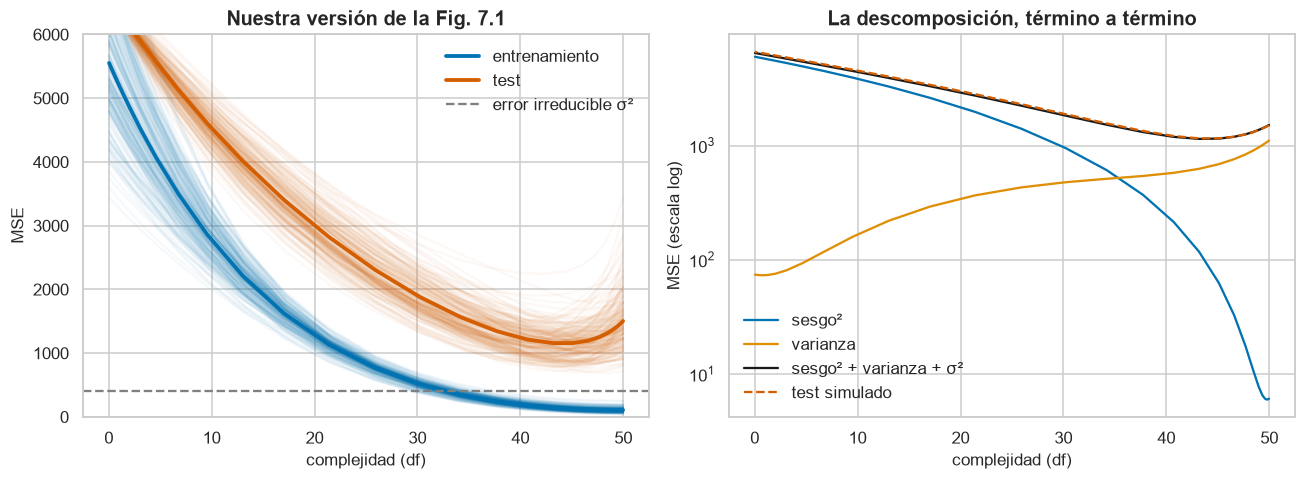

Mínimo del test: alpha = 4.0, df = 43.2, MSE = 1156


In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
for r in range(R):
    axs[0].plot(df[r], err_train[r], color=colores[0], alpha=0.04)
    axs[0].plot(df[r], err_test[r], color=colores[3], alpha=0.04)
axs[0].plot(df_medio, err_train.mean(0), color=colores[0], lw=2.5, label="entrenamiento")
axs[0].plot(df_medio, err_test.mean(0), color=colores[3], lw=2.5, label="test")
axs[0].axhline(sigma**2, color="gray", ls="--", label="error irreducible σ²")
axs[0].set(xlabel="complejidad (df)", ylabel="MSE", ylim=(0, 6000), title="Nuestra versión de la Fig. 7.1")
axs[0].legend()

axs[1].plot(df_medio, sesgo2, label="sesgo²")
axs[1].plot(df_medio, varianza, label="varianza")
axs[1].plot(df_medio, sesgo2 + varianza + sigma**2, color="k", label="sesgo² + varianza + σ²")
axs[1].plot(df_medio, err_test.mean(0), color=colores[3], ls="--", label="test simulado")
axs[1].set(xlabel="complejidad (df)", ylabel="MSE (escala log)", yscale="log", title="La descomposición, término a término")
axs[1].legend(); plt.tight_layout(); plt.show()

j = err_test.mean(0).argmin()
print(f"Mínimo del test: alpha = {alphas[j]:.1f}, df = {df_medio[j]:.1f}, MSE = {err_test.mean(0)[j]:.0f}")

**Qué mirar.** A la izquierda está la Fig. 7.1 reconstruida. El error de entrenamiento baja hasta quedar **por debajo de $\sigma_\varepsilon^2 = 400$** cuando $df \to 50$: el modelo se aprende el ruido, cosa que ningún predictor honesto puede hacer. El de test hace la U, y las curvas rojas finas se abren a la derecha. En el panel derecho, al crecer $df$ el sesgo² cae y la varianza sube, y la suma negra se apoya sobre el test simulado. **La descomposición cierra con números.** Las diferencias chicas salen de usar 200 $\tau$ y 1000 puntos de test en vez de infinitos.

Un detalle: con $\alpha \to \infty$ la varianza no llega a cero, se planta cerca de 90. Ridge no penaliza el intercepto, así que en el extremo predice $\bar y$, y $\bar y$ cambia de un $\tau$ a otro.

### ⚠️ Confusión típica

"Varianza" acá **no** es $\mathrm{Var}(Y)$ ni la varianza de los residuos. Es cuánto cambia **la predicción en un $x$ fijo** cuando cambia el conjunto de entrenamiento. Y el sesgo no es de "un" modelo: es la distancia entre la predicción **promedio** sobre todos los $\tau$ y la verdad. Un $\tau$ suelto no tiene ni sesgo ni varianza.

## 4. Sesgo y varianza en cuentas: OLS y Ridge

📓 celdas 35–42 · 📕 ESL §7.3 · §3.4.1 (grados de libertad de Ridge)

### La idea en criollo

La §3 dio la descomposición en general. Acá la calculamos para los dos modelos que ya conocés, y aparece una regla muy concreta: **cada parámetro que agregás le suma $\sigma_\varepsilon^2/N$ a la varianza**. Ridge baja esa cuenta **encogiendo** de a poco las direcciones de $\mathbf{X}$ con menos información. La clase dice que las "apaga".

> **Dónde se rompe "apagar".** Ridge nunca deja una dirección en cero exacto: la achica. Dejar coeficientes en cero es lo que hace Lasso (clase 5).

### Formalizándolo

**Cambio de escenario (celda 35).** Para que las cuentas cierren, la clase **fija los $x_i$** del entrenamiento: lo único aleatorio son las $y_i$, o sea el ruido. Es el mismo supuesto de ESL §7.3. La esperanza ya no es sobre $\tau$ entero sino sobre las $y$.

**OLS en un punto $x_0$ (celdas 35–36).** Con $Y = f(x_0) + \varepsilon$, desarrollamos $E[(f(x_0) + \varepsilon - \hat f(x_0))^2]$. El cruzado $2\,E[\varepsilon\,(f(x_0) - \hat f(x_0))]$ se anula porque el $\varepsilon$ del punto **nuevo** es independiente de $\hat f$, que solo usó el ruido del entrenamiento, y $E[\varepsilon] = 0$. Después se repite el truco de sumar y restar $E[\hat f(x_0)]$. Resultado:

$$Err(x_0) = \underbrace{(f(x_0) - E[\hat f(x_0)])^2}_{\text{sesgo}^2} + \underbrace{\mathrm{Var}(\hat f(x_0))}_{\text{varianza}} + \sigma_\varepsilon^2.$$

**La varianza (celdas 37–38).** La predicción de OLS es

$$\hat f(x_0) = x_0^T(\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T\mathbf{y} = \mathbf{h}(x_0)^T\mathbf{y}, \qquad \mathbf{h}(x_0) = \mathbf{X}(\mathbf{X}^T\mathbf{X})^{-1}x_0.$$

$\mathbf{h}(x_0)$ es un vector de $N$ **pesos**: la predicción en $x_0$ es un promedio ponderado de las $y_i$ del entrenamiento. Como $\mathbf{X}$ está fijo, $\mathbf{h}(x_0)$ es constante, y para un vector constante $\mathbf{a}$ vale $\mathrm{Var}(\mathbf{a}^T\mathbf{y}) = \mathbf{a}^T\,\mathrm{Cov}(\mathbf{y})\,\mathbf{a}$. Los errores son **independientes**, así que la covarianza entre $y_i$ e $y_j$ es $0$ fuera de la diagonal. Son **homocedásticos**, así que la diagonal es toda $\sigma_\varepsilon^2$. Entonces $\mathrm{Cov}(\mathbf{y}) = \sigma_\varepsilon^2\mathbf{I}$ y

$$\mathrm{Var}(\hat f(x_0)) = \sigma_\varepsilon^2\,\mathbf{h}(x_0)^T\mathbf{h}(x_0) = \sigma_\varepsilon^2\,\|\mathbf{h}(x_0)\|^2.$$

**El promedio en los puntos de entrenamiento (celdas 39–40).** La clase dice "se puede mostrar que $\sum_i \|\mathbf{h}(x_i)\|^2 = p$". Mostrémoslo en tres pasos.

1. $x_i^T$ es la fila $i$ de $\mathbf{X}$, así que $\mathbf{h}(x_i) = \mathbf{X}(\mathbf{X}^T\mathbf{X})^{-1}x_i$ es la **columna $i$** de la matriz sombrero $\mathbf{H} = \mathbf{X}(\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T$. Es la de la clase 2, la que "le pone el sombrero" a $\mathbf{y}$: $\hat{\mathbf{y}} = \mathbf{H}\mathbf{y}$.
2. $\mathbf{H}$ es **simétrica** ($\mathbf{H}^T = \mathbf{H}$) e **idempotente**: $\mathbf{H}\mathbf{H} = \mathbf{X}(\mathbf{X}^T\mathbf{X})^{-1}\underbrace{\mathbf{X}^T\mathbf{X}(\mathbf{X}^T\mathbf{X})^{-1}}_{\mathbf{I}}\mathbf{X}^T = \mathbf{H}$. Proyectar dos veces es proyectar una. Entonces $\|\mathbf{h}(x_i)\|^2 = (\mathbf{H}^T\mathbf{H})_{ii} = (\mathbf{H}\mathbf{H})_{ii} = H_{ii}$.
3. Sumando, $\sum_i H_{ii} = \mathrm{tr}(\mathbf{H})$. Con la propiedad cíclica de la traza, $\mathrm{tr}(\mathbf{A}\mathbf{B}) = \mathrm{tr}(\mathbf{B}\mathbf{A})$: $\mathrm{tr}(\mathbf{X}\,[(\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T]) = \mathrm{tr}((\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T\mathbf{X}) = \mathrm{tr}(\mathbf{I}_p) = p$.

Queda el resultado de la celda 40. ESL §7.3 lo llama **error *in-sample***: es el $Err_{in}$ de la §5.

$$\frac{1}{N}\sum_{i=1}^N Err(x_i) = \frac{1}{N}\sum_{i=1}^N (f(x_i) - E[\hat f(x_i)])^2 + \frac{p}{N}\sigma_\varepsilon^2 + \sigma_\varepsilon^2.$$

La celda 40 pregunta *¿por qué el sesgo no es cero?* Si $f$ **es** lineal en las variables que usás, OLS es insesgado: $E[\hat\beta] = \beta$, entonces $E[\hat f(x_i)] = x_i^T\beta = f(x_i)$ y el sesgo es cero. Si $f$ no es lineal, el mejor hiperplano igual le erra. Ese error no baja con más datos, porque es una limitación del **tipo de modelo**.

**Ridge (celda 41).** Se cambia $\mathbf{h}$ por $\mathbf{X}(\mathbf{X}^T\mathbf{X} + \alpha\mathbf{I})^{-1}x_0$. La matriz sombrero de Ridge es $\mathbf{H}_\alpha = \mathbf{X}(\mathbf{X}^T\mathbf{X} + \alpha\mathbf{I})^{-1}\mathbf{X}^T$: la de OLS con el $+\alpha\mathbf{I}$. Con la SVD $\mathbf{X} = \mathbf{U}\mathbf{D}\mathbf{V}^T$ de la clase 4, la línea clave es $(\mathbf{X}^T\mathbf{X} + \alpha\mathbf{I})^{-1} = \mathbf{V}(\mathbf{D}^2 + \alpha\mathbf{I})^{-1}\mathbf{V}^T$. Sustituyendo, y usando $\mathbf{V}^T\mathbf{V} = \mathbf{I}$:

$$\hat{\mathbf{y}} = \mathbf{H}_\alpha\mathbf{y}, \qquad \mathbf{H}_\alpha = \mathbf{U}\,\mathrm{diag}(s_j)\,\mathbf{U}^T, \qquad s_j = \frac{d_j^2}{d_j^2 + \alpha} \in (0, 1].$$

$s_j$ es el **factor de encogimiento** de la dirección $j$: cuánto se deja pasar de la componente de $\mathbf{y}$ en esa dirección. $\mathbf{H}_\alpha$ es simétrica pero **ya no es idempotente**, así que repetimos el paso 2 a mano:

$$\sum_i \|\mathbf{h}(x_i)\|^2 = \mathrm{tr}(\mathbf{H}_\alpha^T\mathbf{H}_\alpha) = \mathrm{tr}(\mathbf{U}\,\mathrm{diag}(s_j^2)\,\mathbf{U}^T) = \mathrm{tr}(\mathrm{diag}(s_j^2)\,\mathbf{U}^T\mathbf{U}) = \sum_j s_j^2 = \sum_j \frac{d_j^4}{(d_j^2 + \alpha)^2}.$$

Así sale la varianza de la celda 41. Con $\alpha = 0$ todos los $s_j$ valen 1 y la suma vuelve a ser $p$. Ojo con un detalle: los **grados de libertad efectivos** son la traza de $\mathbf{H}_\alpha$, sin elevar al cuadrado: $df(\alpha) = \sum_j s_j$ (ESL §3.4.1). Es el eje x de los gráficos de la §3. Las dos sumas valen $p$ en $\alpha = 0$ y bajan con $\alpha$, pero no son iguales.

**El sesgo de Ridge (celdas 41–42).** Acá cambia el escenario: $x_0$ ya no es un punto de entrenamiento, se promedia sobre toda la población, como en ESL §7.3. $\beta_*$ es el **mejor modelo lineal posible**: el que minimiza $E_X[(f(X) - X^T\beta)^2]$ si conocieras toda la población. Sumamos y restamos $x_0^T\beta_*$ dentro del sesgo:

$$E_{x_0}\big[(f(x_0) - E\hat f_\alpha(x_0))^2\big] = \underbrace{E_{x_0}\big[(f(x_0) - x_0^T\beta_*)^2\big]}_{\text{sesgo del modelo}^2} + \underbrace{E_{x_0}\big[(x_0^T\beta_* - E[x_0^T\hat\beta_\alpha])^2\big]}_{\text{sesgo de estimación}^2}.$$

**Línea clave:** el cruzado es $2\,E_{x_0}[(f(x_0) - x_0^T\beta_*)\,x_0^T]\,(\beta_* - E\hat\beta_\alpha)$, y su primer factor vale cero. Es la condición de óptimo de $\beta_*$ (derivar e igualar a cero): la ecuación normal en versión poblacional.

- El **sesgo del modelo** solo baja si cambiás de familia (más variables, interacciones, otro modelo). Si $f$ es lineal, vale cero. En nuestro mundo es así.
- El **sesgo de estimación** es cero para OLS cuando $f$ es lineal, como en nuestro mundo. ESL lo da como cero para OLS en general. Para Ridge es positivo. Es lo que Ridge paga para bajar la varianza.

### ¿Por qué nos importa?

Porque la cuenta $\frac{p}{N}\sigma_\varepsilon^2$ cuantifica el sobreajuste. En nuestro mundo, $p = 51$ (50 variables más el intercepto) y $N = 70$, así que la varianza es $\frac{51}{70} \cdot 400 \approx 291$: casi tanto como el ruido mismo. Y te da la lectura correcta de Ridge: cambia sesgo de estimación por varianza, dirección por dirección, y empieza por las de $d_j$ chico.

> **Para el parcial, en frío:** (a) $Err(x_0)$ = sesgo² + varianza + $\sigma_\varepsilon^2$, diciendo por qué muere cada cruzado; (b) $\mathrm{Var}(\hat f(x_0)) = \sigma_\varepsilon^2\|\mathbf{h}(x_0)\|^2$; (c) $\sum_i \|\mathbf{h}(x_i)\|^2 = \mathrm{tr}(\mathbf{H}) = p$, con simetría, idempotencia y traza cíclica. Como **resultado** alcanza con saber $\sum_j s_j^2$ para Ridge y la partición del sesgo en modelo + estimación.

### En código

Fijamos un $\mathbf{X}$ y generamos 4000 vectores $\mathbf{y}$ distintos. Medimos la varianza de $\hat f(x_i)$ y la comparamos con la fórmula:

In [7]:
X_fijo, _ = muestrear(N)                          # el diseño queda fijo; solo el ruido varía (celda 35)
f_train = X_fijo @ beta_true
alphas_chk = np.array([0.0, 10.0, 100.0])
M = 4000
ys = f_train + sigma * rng.standard_normal((M, N))
ajustes = np.zeros((M, len(alphas_chk), N))       # f_hat(x_i) para cada y, cada alpha, cada i
for m in range(M):
    B, b0, d = ridge(X_fijo, ys[m], alphas_chk)
    ajustes[m] = (X_fijo @ B + b0).T

s = d[:, None]**2 / (d[:, None]**2 + alphas_chk)   # factores de encogimiento s_j
var_sim = ajustes.var(axis=0).mean(axis=1)         # Var(f_hat(x_i)), promediada sobre i
var_formula = sigma**2 / N * (1 + (s**2).sum(axis=0))  # el +1 es el intercepto, un parámetro más
for a, dfa, vs, vf in zip(alphas_chk, s.sum(axis=0), var_sim, var_formula):
    print(f"alpha = {a:5.0f}   df + 1 = {1 + dfa:4.1f}   varianza simulada = {vs:5.1f}   fórmula = {vf:5.1f}")

alpha =     0   df + 1 = 51.0   varianza simulada = 289.1   fórmula = 291.4
alpha =    10   df + 1 = 38.5   varianza simulada = 177.9   fórmula = 179.6
alpha =   100   df + 1 = 18.0   varianza simulada =  50.3   fórmula =  51.0


La columna `df + 1` suma el intercepto, que Ridge no encoge. Con $\alpha = 0$ es OLS: $\frac{51}{70} \cdot 400 \approx 291$. La simulación coincide con la fórmula en los tres casos. Al subir $\alpha$, $df$ y la varianza bajan juntos, pero la varianza baja más rápido, porque usa $s_j^2$ en vez de $s_j$.

### ⚠️ Confusión típica

"Ridge con 50 coeficientes tiene 50 parámetros." Tiene 50 coeficientes, todos distintos de cero, pero su complejidad efectiva es $df(\alpha)$, que puede ser 3. En Ridge, la complejidad no se cuenta en coeficientes.

Y una sutileza: $\frac{p}{N}\sigma_\varepsilon^2$ es la varianza **promediada en los puntos de entrenamiento**. En un $x_0$ nuevo, sobre todo uno lejos de los datos, $\|\mathbf{h}(x_0)\|^2$ puede ser mucho más grande.

## 5. ¿Qué error estamos midiendo?

📓 celdas 34, 43–48 · 📕 ESL §7.2, §7.4, §7.12

### La idea en criollo

Pensá en estudiar con una guía de ejercicios. Cada error de la clase corresponde a una nota distinta:

- $\overline{err}$ es tu nota en **los mismos ejercicios** de la guía que ya resolviste.
- $Err_{in}$ es tu nota en los mismos ejercicios **con otros números**.
- $Err_\tau$ es tu nota en un **examen nuevo**, habiendo estudiado con *tu* guía.
- $Err$ es la nota promedio de todos los alumnos que estudiaron con guías distintas del mismo tamaño.

> **Dónde se rompe la analogía.** Un alumno puede entender y generalizar a propósito. Un modelo solo ajusta lo que la pérdida le pide. Y en $Err_{in}$ cambian solo las respuestas ($y$), no las preguntas ($x$). Por eso en el ejemplo los números cambian pero el enunciado queda igual.

### Formalizándolo

| Error | Definición | Qué queda fijo | Sobre qué se promedia |
|---|---|---|---|
| $\overline{err}$ | $\frac{1}{N}\sum_i L(y_i, \hat f(x_i))$ | todo: es un número que **calculás** | nada |
| $Err_\tau$ | $E_{X^0, Y^0}[L(Y^0, \hat f(X^0)) \mid \tau]$ | $\tau$, y por lo tanto $\hat f$ | un punto nuevo $(X^0, Y^0)$ |
| $Err$ | $E_\tau[Err_\tau]$ | nada | $\tau$ y el punto nuevo |
| $Err_{in}$ | $\frac{1}{N}\sum_i E_{Y^0}[L(Y_i^0, \hat f(x_i)) \mid \tau]$ | $\tau$ y los $x_i$ | respuestas nuevas $Y_i^0$ en los mismos $x_i$ |

El superíndice $^0$ marca un dato **nuevo**, que el modelo no vio. ESL escribe $Err_{\mathcal{T}}$ donde la clase escribe $Err_\tau$.

**Las preguntas de las celdas 34 y 43: ¿cuáles estimamos en la §3? ¿Cuál descomponemos?**

- Cada curva **roja fina** estima $Err_\tau$ para *ese* $\tau$: el modelo queda fijo y se evalúa en 1000 puntos nuevos.
- La **roja gruesa** promedia 200 de esas, así que estima $Err$.
- Las **celestes finas** son $\overline{err}$, calculado exactamente. La gruesa estima $E_\tau[\overline{err}]$.
- Lo que **descomponemos** es $Err$. La varianza es una varianza **sobre $\tau$**, así que con un $\tau$ fijo no hay nada que descomponer. En la §4, con $\mathbf{X}$ fijo, "sobre $\tau$" se reduce a "sobre las $\mathbf{y}$".

**El optimismo (celda 46).** $op = Err_{in} - \overline{err}$ mide cuánto te miente el error de entrenamiento. ESL §7.4 calcula su promedio sobre las $y$, $\omega = E_y[op]$. Para pérdida cuadrática la cuenta es corta. Para cada $i$ comparamos $E[(Y_i^0 - \hat y_i)^2]$ con $E[(y_i - \hat y_i)^2]$:

- Expandimos los dos cuadrados. $\hat y_i^2$ aparece en los dos y se cancela.
- $Y_i^0$ e $y_i$ tienen la misma distribución, así que $E[(Y_i^0)^2] = E[y_i^2]$ y también se cancela.
- Queda $2E[y_i\hat y_i] - 2E[Y_i^0\hat y_i]$. $Y_i^0$ es independiente de $\hat y_i$, que no lo vio, así que $E[Y_i^0\hat y_i] = E[Y_i^0]E[\hat y_i] = E[y_i]E[\hat y_i]$.
- La diferencia es $2(E[y_i\hat y_i] - E[y_i]E[\hat y_i]) = 2\,\mathrm{Cov}(\hat y_i, y_i)$.

Promediando sobre $i$:

$$\omega = \frac{2}{N}\sum_{i=1}^N \mathrm{Cov}(\hat y_i, y_i).$$

El optimismo es grande cuando **cada $y_i$ empuja a su propia predicción**: el modelo se adapta a su ruido. Para un ajuste lineal $\hat{\mathbf{y}} = \mathbf{H}\mathbf{y}$, $\mathrm{Cov}(\hat y_i, y_i) = \mathrm{Cov}(\sum_j H_{ij}y_j,\, y_i) = H_{ii}\sigma_\varepsilon^2$, porque los $y_j$ con $j \neq i$ son independientes de $y_i$. Sumando, sale $\mathrm{tr}(\mathbf{H})\sigma_\varepsilon^2$:

$$\omega = \frac{2\,df\,\sigma_\varepsilon^2}{N}.$$

Otra vez la traza: $p$ para OLS y $df(\alpha)$ para Ridge.

> **Para el parcial, en frío:** la cuenta de $\omega = \frac{2}{N}\sum_i \mathrm{Cov}(\hat y_i, y_i)$ (cuatro líneas) y su versión lineal, con la línea clave $\mathrm{Cov}(\hat y_i, y_i) = H_{ii}\sigma_\varepsilon^2$.

**La aclaración de la celda 48** ("no estamos respetando la definición de optimismo") viene de acá. $C_p$, AIC y BIC corrigen $\overline{err}$ sumándole una estimación de $\omega$, que es el optimismo **promedio**, no el $op$ de tu $\tau$ particular. Por ejemplo, $C_p = \overline{err} + 2\frac{d}{N}\hat\sigma_\varepsilon^2$ (ESL §7.5). La CV y el bootstrap, en cambio, apuntan directo a $Err$, el error *extra-sample*.

### ❓ La pregunta que quedó abierta

**Celda 47: ¿cuál error queremos estimar y por qué?** El que te importa es $Err_\tau$: vas a usar **tu** modelo, entrenado con **tu** $\tau$. El problema es que estimarlo con los mismos datos de $\tau$ es muy difícil. ESL §7.12 concluye que la CV y sus parientes estiman bien $Err$, no $Err_\tau$ (lo vemos en la §6). Por eso la receta guarda un test: con $\tau$ y $\hat f$ fijos, el promedio de la pérdida en datos nuevos **es** un estimador insesgado de $Err_\tau$.

Para **elegir** alcanza con menos. Importa el **orden** entre modelos, no el valor absoluto. Por eso la celda 48 dice que $Err_{in}$ suele elegir bien aunque los $x$ futuros no vayan a coincidir con los de entrenamiento.

### En código

Volvemos al $\mathbf{X}$ fijo y a las 4000 $\mathbf{y}$ de la §4. $Err_{in}$ se calcula exacto: $E_{Y^0}[(Y_i^0 - \hat y_i)^2] = \sigma_\varepsilon^2 + (f(x_i) - \hat y_i)^2$, por el mismo argumento del cruzado de la §3.

In [8]:
err_barra = ((ys[:, None, :] - ajustes)**2).mean(axis=2)            # error de entrenamiento, por y
err_in = sigma**2 + ((f_train - ajustes)**2).mean(axis=2)          # mismos x_i, respuestas nuevas
omega_sim = (err_in - err_barra).mean(axis=0)                      # promedio de op sobre las y
omega_formula = 2 * (1 + s.sum(axis=0)) * sigma**2 / N             # 2 df sigma^2 / N (+1 intercepto)
for a, o_s, o_f, eb in zip(alphas_chk, omega_sim, omega_formula, err_barra.mean(axis=0)):
    print(f"alpha = {a:5.0f}   err_barra medio = {eb:5.0f}   optimismo simulado = {o_s:5.0f}   2·df·σ²/N = {o_f:5.0f}")

alpha =     0   err_barra medio =   109   optimismo simulado =   580   2·df·σ²/N =   583
alpha =    10   err_barra medio =   264   optimismo simulado =   438   2·df·σ²/N =   440
alpha =   100   err_barra medio =  1440   optimismo simulado =   207   2·df·σ²/N =   206


Con OLS ($\alpha = 0$), el error de entrenamiento promedio queda muy por debajo de $\sigma_\varepsilon^2 = 400$, y el optimismo es de casi 600: mayor que el propio ruido. La fórmula $2\,df\,\sigma_\varepsilon^2/N$ lo clava en los tres $\alpha$. Con $df$ cerca de $N$, el error de entrenamiento no sirve para nada.

### ⚠️ Confusión típica

Confundir $Err_{in}$ con el error de test. $Err_{in}$ usa **los mismos $x_i$**: no mide cómo le va al modelo en zonas nuevas del espacio. Y $\overline{err}$ no se "estima", se **calcula**: es un número exacto sobre tus datos, solo que mide otra cosa que la que te importa.

## 6. Validación cruzada K-fold

📓 celdas 49–53 · 📕 ESL §7.10, §7.12

### La idea en criollo

Dividís el curso en 5 grupos. Las tareas de cada grupo se corrigen con una grilla que armaron **los otros 4** grupos. Así, cada tarea la corrige alguien que no la vio de antemano, y nadie se corrige a sí mismo.

> **Dónde se rompe la analogía.** Al final no usás ninguna de las 5 grillas: armás una nueva con **todo** el curso. La CV evaluó **cinco modelos distintos** del que vas a entregar, cada uno entrenado con menos datos. Lo que mide es qué tan bueno es el **procedimiento** de entrenar con datos de este tamaño, no tu modelo final. Esa es exactamente la razón por la que estima $Err$ y no $Err_\tau$.

### Formalizándolo

La celda 49 define dos objetos:

- $\kappa: \{1, \ldots, N\} \to \{1, \ldots, K\}$ ("kappa") le asigna a cada muestra $i$ el fold al que pertenece.
- $\hat f^{-k}$ es el modelo entrenado **sin** el fold $k$.

Con $L(y, \hat y)$ la pérdida de una muestra (acá, $(y - \hat y)^2$):

$$CV(\hat f) = \frac{1}{N}\sum_{i=1}^N L\big(y_i, \hat f^{-\kappa(i)}(x_i)\big).$$

Leelo de adentro hacia afuera. Para la muestra $i$ buscás su fold $\kappa(i)$, usás el modelo que **no** vio ese fold, y calculás la pérdida.

**La pregunta de la celda 49: el promedio es sobre las muestras, no sobre los folds. ¿Qué significa?** Agrupá la suma por fold. Si el fold $k$ tiene $N_k$ muestras y error medio $\bar L_k$,

$$CV(\hat f) = \sum_{k=1}^K \frac{N_k}{N}\,\bar L_k.$$

Cada **muestra** pesa lo mismo, y cada fold pesa según su tamaño. En qué caso esto coincide con el promedio simple de los $\bar L_k$ te lo dejo para el ejercicio 4.

**Para elegir un hiperparámetro (celda 50).** Repetís todo con cada $\alpha$:

$$CV(\hat f, \alpha) = \frac{1}{N}\sum_{i=1}^N L\big(y_i, \hat f^{-\kappa(i)}(x_i, \alpha)\big), \qquad \hat\alpha = \arg\min_\alpha CV(\hat f, \alpha).$$

Después reentrenás con $\hat\alpha$ y **todos** los datos: es el paso 4 de la receta.

**¿Qué pasa con K? (celdas 51–52).** Cada $\hat f^{-k}$ se entrena con $N\frac{K-1}{K}$ datos, no con $N$. De ahí sale el compromiso:

- **$K = N$**, *leave-one-out*. Cada modelo usa $N - 1$ datos, casi todo, así que el sesgo es mínimo. Pero los $N$ conjuntos de entrenamiento son casi idénticos, y los errores que promediás están muy correlacionados. Promediar cosas correlacionadas no baja la varianza: **alta varianza** y $N$ ajustes.
- **$K = 5$ o $10$**. Los conjuntos se solapan menos, así que hay menos varianza y es más barato. Pero cada modelo ve un 20 % o un 10 % menos de datos, y eso trae **sesgo hacia arriba**: la CV sobreestima el error.

#### 🖼️ La figura de la clase

![Curva de aprendizaje hipotética (ESL Fig. 7.8)](../../figuras/curva_de_aprendizaje.png)

Es la **Fig. 7.8 de ESL**: $1 - Err$, la tasa de acierto, en función del tamaño del entrenamiento. Mirá dónde cae $N\frac{K-1}{K}$. Con $N = 200$ y $K = 5$ cae en 160, en la zona plana, y casi no hay sesgo. Con $N = 50$ cae en 40, donde la curva sube, y la CV **sobreestima** el error. **El sesgo de la CV depende de la pendiente de la curva de aprendizaje en tu $N$.**

### En código

En nuestro mundo, con un único $\tau$, como en la vida real, implementamos $\kappa$ y la fórmula tal cual:

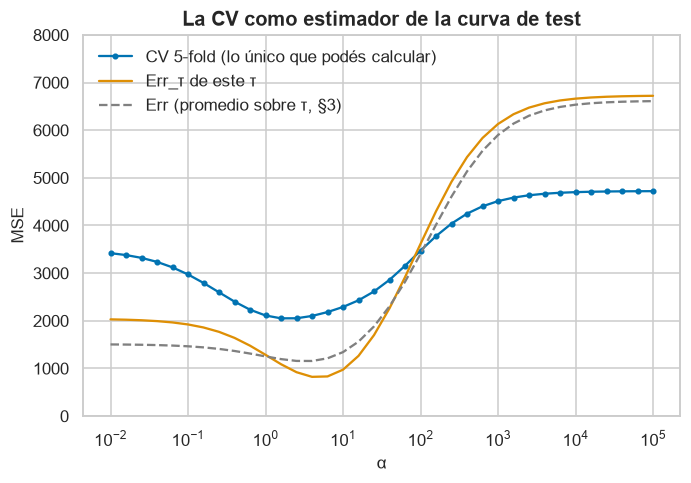

alpha elegido por CV: 1.6   ·   mejor alpha para este tau: 4.0


In [9]:
def cv_ridge(X, y, alphas, K=5, seed=0):
    # CV(f_hat, alpha): cada muestra evaluada por el modelo que no la vio, promedio sobre las N muestras
    kappa = np.random.default_rng(seed).permutation(len(y)) % K   # kappa(i) = fold de la muestra i
    perdidas = np.zeros((len(y), len(alphas)))
    for k in range(K):
        fuera = kappa == k
        B, b0, _ = ridge(X[~fuera], y[~fuera], alphas)             # f_hat^{-k}
        perdidas[fuera] = (y[fuera, None] - (X[fuera] @ B + b0))**2
    return perdidas.mean(axis=0)

X, y = muestrear(N)                                  # nuestro único tau
cv = cv_ridge(X, y, alphas)
B, b0, _ = ridge(X, y, alphas)
err_tau = ((y_test[:, None] - (X_test @ B + b0))**2).mean(axis=0)  # requiere datos nuevos

fig, ax = plt.subplots()
ax.plot(alphas, cv, "o-", ms=3, label="CV 5-fold (lo único que podés calcular)")
ax.plot(alphas, err_tau, label="Err_τ de este τ")
ax.plot(alphas, err_test.mean(0), ls="--", color="gray", label="Err (promedio sobre τ, §3)")
ax.set(xscale="log", xlabel="α", ylabel="MSE", ylim=(0, 8000), title="La CV como estimador de la curva de test")
ax.legend(); plt.show()
print(f"alpha elegido por CV: {alphas[cv.argmin()]:.1f}   ·   mejor alpha para este tau: {alphas[err_tau.argmin()]:.1f}")

La curva de CV tiene la forma correcta: es alta en los extremos, tiene un valle en el medio y elige un $\alpha$ razonable. Pero fijate a la izquierda ($\alpha$ chico, casi OLS): la CV queda **muy por encima** de las otras dos. Es el sesgo de la Fig. 7.8 en vivo. Cada fold entrena con 56 datos para 51 parámetros, en vez de 70, y en ese régimen la curva de aprendizaje es empinadísima.

A la derecha pasa lo contrario: la CV queda **por debajo**. Con $\alpha$ enorme el modelo predice casi $\bar y$, y la CV mide cuán dispersas están las $y$ de **este** $\tau$. Por azar, en este $\tau$ están menos dispersas que en la población. Esa es la variabilidad de la CV que vamos a medir abajo.

##### 🏭 Así se hace en la industria

`GridSearchCV` hace el mismo loop. Con folds de igual tamaño (14 muestras), su promedio por fold coincide con nuestro promedio por muestra:

In [10]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, KFold

busqueda = GridSearchCV(Ridge(), {"alpha": alphas}, scoring="neg_mean_squared_error",
                        cv=KFold(n_splits=5, shuffle=True, random_state=0)).fit(X, y)
print(f"alpha elegido por GridSearchCV: {busqueda.best_params_['alpha']:.1f}")
print(f"CV en ese alpha: {-busqueda.best_score_:.0f}")   # sklearn maximiza, por eso el MSE viene negado

alpha elegido por GridSearchCV: 1.6
CV en ese alpha: 1531


Sklearn sortea los folds distinto, así que la curva no es idéntica punto a punto, pero el $\alpha$ elegido sale del mismo valle.

### ❓ La pregunta que quedó abierta

**Celda 53: la CV estima $Err$, no $Err_\tau$. ¿Por qué?** Por dos razones. Los $K$ modelos que evalúa no son tu modelo: se entrenaron con otros subconjuntos. Y con un solo $\tau$ no hay manera de saber si te tocó un $\tau$ "bueno" o "malo": la CV ve las mismas muestras que hicieron a tu modelo como es. ESL §7.12 lo mide: entre muchos $\tau$, la correlación entre la CV y el $Err_\tau$ verdadero es casi nula, e incluso negativa. Lo verificamos en nuestro mundo, con un $\alpha$ fijo:

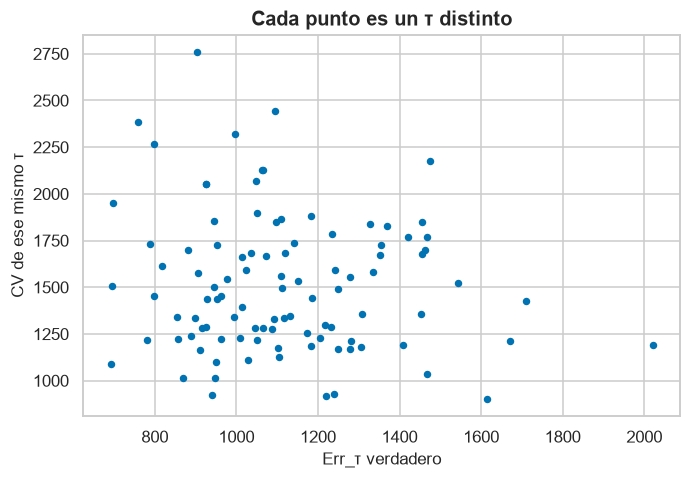

promedio de CV = 1516   ·   promedio de Err_tau = 1117
correlación entre CV y Err_tau, tau a tau = -0.13


In [11]:
a = np.array([alphas[err_test.mean(0).argmin()]])     # fijo: el mejor alpha en promedio (§3)
cvs, errs = np.zeros(100), np.zeros(100)
for r in range(100):
    X, y = muestrear(N)
    cvs[r] = cv_ridge(X, y, a, seed=r)[0]
    B, b0, _ = ridge(X, y, a)
    errs[r] = ((y_test - (X_test @ B + b0)[:, 0])**2).mean()

fig, ax = plt.subplots()
ax.scatter(errs, cvs, s=15, color=colores[0])
ax.set(xlabel="Err_τ verdadero", ylabel="CV de ese mismo τ", title="Cada punto es un τ distinto")
plt.show()
print(f"promedio de CV = {cvs.mean():.0f}   ·   promedio de Err_tau = {errs.mean():.0f}")
print(f"correlación entre CV y Err_tau, tau a tau = {np.corrcoef(cvs, errs)[0, 1]:.2f}")

La nube no tiene pendiente. Que tu CV dé alto o bajo **no te dice** si tu $Err_\tau$ es alto o bajo. Lo que sí hace la CV es apuntar al nivel **promedio**, pero acá queda por arriba de $Err$ por el sesgo de entrenar con 56 datos en vez de 70. En un problema con la curva de aprendizaje más plana, ese sesgo se achica. ESL §7.12 cierra igual: estimar el error de test de **un** conjunto de entrenamiento con sus propios datos no es fácil en general, y la CV da estimaciones razonables del error **esperado** $Err$.

**"Ejemplos del libro" (celda 53).** La clase los deja nombrados. Son dos y vale la pena leerlos:

- ESL §7.10.2, *la forma incorrecta de hacer CV*: el caso de seleccionar variables antes de partir, que vimos en la §1.
- ESL §7.10.3: una simulación que muestra que, hecha bien (reajustando **todo** dentro de cada fold), la CV da el 50 % de error correcto incluso con 500 predictores y 20 muestras.

### ⚠️ Confusión típica

Hacer cualquier paso que aprende de los datos (estandarizar, imputar, elegir variables) **antes** de partir en folds. Cada fold tiene que repetir **todo** el pipeline viendo solo su parte de entrenamiento. En sklearn eso se logra metiendo los pasos en un `Pipeline` y pasándole el `Pipeline` a `GridSearchCV`.

## 🧵 El hilo conductor

La clase arranca con una alarma: si elegís entre muchos modelos con un número ruidoso, el ganador miente. Para entender **qué** número es el que miente y cuál no, hace falta separar las fuentes del error. Con pérdida cuadrática el blanco es $E(Y \mid X)$, como en la teoría de la decisión de la clase 1. Lo que queda después de acertarle es ruido irreducible. Y lo que separa a tu modelo del blanco se parte en sesgo (le apunta mal en promedio) y varianza (cambia con cada $\tau$).

Las clases 2 a 5 aparecen ahora como **casos** de esa descomposición. OLS tiene sesgo cero si el mundo es lineal, pero paga $\frac{p}{N}\sigma_\varepsilon^2$ de varianza: la traza de la matriz sombrero, que la clase 2 presentó como proyección. Ridge y Lasso (clases 4 y 5) son maneras de comprar menos varianza con un poco de sesgo de estimación. $df(\alpha)$ mide cuánta complejidad queda, y $\alpha$ es la perilla.

Lo que falta es saber **dónde poner la perilla** sin conocer $f$. El error de entrenamiento no sirve: es optimista en $2\,df\,\sigma_\varepsilon^2/N$. Por eso existen dos familias. Una corrige ese optimismo con fórmulas ($C_p$, AIC, BIC; ESL §7.5–7.7). La otra lo esquiva evaluando en datos no vistos: la validación cruzada, y el bootstrap de ESL §7.11. Cualquier modelo que veas desde acá (árboles, SVM, redes) se elige y se evalúa con esta receta.

## ✅ Autoevaluación

**1.** ¿Por qué la optimización de hiperparámetros cuenta como selección de modelos?

<details><summary>Respuesta</summary>

Cada valor del hiperparámetro define un modelo distinto, $\hat f(x, \alpha)$. Elegir $\alpha$ es quedarse con el mejor de muchos modelos según un número ruidoso, y por eso hereda el sesgo optimista de la §1. Por la misma razón no se puede usar el test para elegir $\alpha$.

</details>

**2.** Con pérdida absoluta $|Y - c|$, ¿cuál es el mejor $c$ en cada $x$? ¿Qué cambia en la descomposición?

<details><summary>Respuesta</summary>

La **mediana** de $Y \mid X = x$. Con la absoluta, mover $c$ un poquito cambia la pérdida en $+1$ por cada punto que queda de un lado y en $-1$ por cada uno del otro. El óptimo está donde quedan la mitad de cada lado. La descomposición sesgo² + varianza + ruido **no** vale tal cual: los cruzados se anulan gracias a que la pérdida es cuadrática. Con otra pérdida no hay una partición tan limpia, y ESL §7.3.1 lo muestra para la pérdida 0-1.

</details>

**3.** En la §3, ¿por qué el término cruzado del paso 2 se anula al tomar $E_\tau$, pero no se anularía si tomaras $E_Y$?

<details><summary>Respuesta</summary>

El cruzado es $2(f(x;\tau) - \bar f(x))(\bar f(x) - f(x))$. Lo que se anula en promedio es $f(x;\tau) - \bar f(x)$, y solo cuando promediás sobre **$\tau$**, porque $\bar f$ se definió como $E_\tau[f(x;\tau)]$. Con un $\tau$ fijo, $f(x;\tau) - \bar f(x)$ es un número cualquiera, y promediar en $Y$ no lo toca.

</details>

**4.** En nuestro mundo, con OLS ($\alpha = 0$): $N = 70$, $p = 51$ contando el intercepto, $\sigma_\varepsilon^2 = 400$ y $f$ lineal. Calculá a mano el error *in-sample* esperado, $\omega$ y $E[\overline{err}]$, y compará con la salida de la §5.

<details><summary>Respuesta</summary>

El sesgo es 0 porque $f$ es lineal. El error *in-sample* es $\sigma_\varepsilon^2 + \frac{p}{N}\sigma_\varepsilon^2 = 400 + 291 = 691$. El optimismo es $\omega = 2\frac{p}{N}\sigma_\varepsilon^2 \approx 583$, así que $E[\overline{err}] \approx 691 - 583 = 108$. La simulación dio 109 y 580. Fijate que $E[\overline{err}] = \sigma_\varepsilon^2(1 - p/N)$: es la razón por la que el estimador insesgado de $\sigma^2$ de la clase 3 divide por $N - p$.

</details>

**5.** Para Ridge con valores singulares $d = (3, 1)$ y $\alpha = 1$, calculá $df(\alpha)$ y $\sum_j s_j^2$. ¿Cuál es mayor y por qué siempre pasa eso?

<details><summary>Respuesta</summary>

$s_1 = 9/10 = 0.9$ y $s_2 = 1/2 = 0.5$. Entonces $df = 1.4$ y $\sum s_j^2 = 0.81 + 0.25 = 1.06$. Siempre $s_j \in (0, 1]$, y para esos números $s_j^2 \leq s_j$. Por eso la suma de cuadrados nunca supera a $df$, y son iguales solo con $\alpha = 0$.

</details>

**6.** Tenés $N = 30$ datos y la curva de aprendizaje de tu problema todavía sube fuerte en $N = 30$. ¿Qué $K$ elegís y qué sesgo esperás?

<details><summary>Respuesta</summary>

Con $K = 5$ cada fold entrena con 24 datos, en una zona donde la curva sube. La CV va a **sobreestimar** el error del modelo final, que entrena con 30. Subir a $K = 10$ (27 datos) o a LOO (29) baja ese sesgo, a cambio de más varianza y más cómputo. Con $N$ tan chico el costo de LOO es aceptable, pero mirá cuánto varía la estimación.

</details>

**7.** ¿Qué pasa si estandarizás $\mathbf{X}$ con la media y el desvío de **todos** los datos y recién después hacés CV?

<details><summary>Respuesta</summary>

Cada fold de validación ya "contaminó" la media y el desvío con los que se transformó el entrenamiento. Con estandarizar el efecto suele ser chico, porque media y desvío no usan $y$. Pero la regla es la misma que en ESL §7.10.2: cualquier paso que se ajusta con datos va **dentro** del loop. Si el paso usa $y$, como elegir variables por su correlación con $y$, el sesgo puede ser enorme: 3 % de error estimado contra 50 % real en el ejemplo del libro.

</details>

**8.** ¿Qué pasa si hacés la CV de la §6 con $K = N$ en nuestro mundo? ¿Esperás que la correlación con $Err_\tau$ mejore?

<details><summary>Respuesta</summary>

El sesgo baja, porque cada modelo entrena con 69 datos en vez de 56, así que el promedio de la CV se acerca a $Err$. Pero la correlación con $Err_\tau$ **no** mejora de manera apreciable. ESL §7.12 encuentra que ni LOO ni 10-fold siguen a $Err_\tau$, y que 10-fold incluso lo hace algo mejor. El problema no es cuánto dato se usa, sino que un solo $\tau$ no tiene información sobre cuán "afortunado" fue.

</details>

**9.** Sin mirar la §5: con $\hat{\mathbf{y}} = \mathbf{H}\mathbf{y}$ y ruido independiente de varianza $\sigma_\varepsilon^2$, derivá $\omega = \frac{2}{N}\sum_i \mathrm{Cov}(\hat y_i, y_i)$ y después su forma lineal. ¿Qué reemplaza a $p$ en Ridge?

<details><summary>Respuesta</summary>

Para cada $i$: $E[(Y_i^0 - \hat y_i)^2] - E[(y_i - \hat y_i)^2]$. Los $\hat y_i^2$ se cancelan, y también $E[(Y_i^0)^2] = E[y_i^2]$ (misma distribución). Queda $2E[y_i\hat y_i] - 2E[Y_i^0]E[\hat y_i]$, que es $2\,\mathrm{Cov}(\hat y_i, y_i)$, porque $Y_i^0$ es independiente de $\hat y_i$ y tiene la misma media que $y_i$. En el caso lineal, $\mathrm{Cov}(\sum_j H_{ij} y_j, y_i) = H_{ii}\sigma_\varepsilon^2$, porque los $y_j$ con $j \ne i$ no covarían con $y_i$. Sumando sale $\omega = 2\,\mathrm{tr}(\mathbf{H})\sigma_\varepsilon^2/N$. En Ridge, $\mathrm{tr}(\mathbf{H}_\alpha) = df(\alpha) = \sum_j s_j$ reemplaza a $p$.

</details>

## 🎯 Centros para los ejercicios

### Ejercicio 1 — Función de regresión y error irreducible a mano

- **De qué va realmente:** hacer con números la §2 y el paso 1 de la §3. Comprobar que el EPE de **cualquier** predictor se parte en "distancia a $f$" más "ruido", sin simulación.
- **Por dónde arrancar:** con $X$ discreta, cada integral contra $p(x)$ es una suma de dos términos con peso $1/2$. Calculá primero $E[Y \mid X = 0]$ y $E[Y \mid X = 1]$, y después $E[Y]$ como promedio de esos dos (ley de la esperanza total).
- **Con qué chequear:** el error irreducible tiene que ser **menor** que el EPE de cualquier predictor constante, porque el mejor predictor posible es $f$. Y la igualdad del ítem 4 tiene que dar **exacta**, no aproximada.
- **⚠️ Dónde te vas a trabar:** en el ítem 3. Calculalo como $\sum_x p(x)\, E[(Y - c)^2 \mid X = x]$, condicional por condicional, sin suponer de antemano qué número tiene que dar.

### Ejercicio 2 — Un estimador de la media con encogimiento

- **De qué va realmente:** es Ridge en miniatura. $\lambda$ encoge el estimador hacia 0: compra menos varianza con sesgo. Es la §4 sin matrices.
- **Por dónde arrancar:** escribí $\hat\mu_\lambda$ como una constante (que depende de $\lambda$ y $N$) por $\bar Y$. Después usá la linealidad de la esperanza y la regla $\mathrm{Var}(cZ) = c^2\mathrm{Var}(Z)$.
- **Con qué chequear:** con $\lambda = 0$ tenés que recuperar $\bar Y$, insesgado, con varianza $\sigma^2/N$. Y el ECM, como función de $\lambda$, tiene que tener la forma de U de la §3. Graficalo con números concretos, por ejemplo $\mu = 1$, $\sigma = 2$, $N = 10$.
- **⚠️ Dónde te vas a trabar:** en el último ítem. Mirá de qué cantidades depende el $\lambda$ óptimo que te dé, y preguntate cuáles de ellas conocés en la práctica.

### Ejercicio 3 — ¿Qué error se está midiendo?

- **De qué va realmente:** aplicar la tabla de la §5. En cada situación, identificar qué queda fijo ($\tau$, los $x_i$) y sobre qué se promedia.
- **Por dónde arrancar:** para cada ítem, hacete tres preguntas. ¿El modelo es uno solo o hay varios? ¿Los puntos de evaluación son los de entrenamiento o nuevos? Si son los mismos $x$, ¿las $y$ son las mismas o nuevas?
- **Con qué chequear:** para cada ítem, anotá qué queda fijo y qué es aleatorio. Si dos ítems te quedan idénticos en esa anotación, revisá. Para los números que salen directo de tus datos, preguntate además qué cantidad teórica están estimando.
- **⚠️ Dónde te vas a trabar:** en el ítem 5. Fijate que dice "se promedian las pérdidas **de cada caso**": revisá la definición de la celda 49. Y en el 3, cuidado con decir que se calcula algo que solo se puede estimar.

### Ejercicio 4 — CV con folds de distinto tamaño

- **De qué va realmente:** la pregunta de la celda 49. Promediar sobre muestras y promediar sobre folds son cosas distintas, y la definición de ESL es la primera.
- **Por dónde arrancar:** contá cuántas muestras tiene cada fold y anotá $N$ total antes de hacer cualquier promedio.
- **Con qué chequear:** usá la fórmula de la §6, $CV = \sum_k \frac{N_k}{N}\bar L_k$. Tenés que llegar al mismo número que sumando las 10 pérdidas y dividiendo por 10.
- **⚠️ Dónde te vas a trabar:** en el ítem 3. No alcanza con decir "porque los folds tienen distinto tamaño". Preguntate qué cambia en la fórmula cuando los pesos $N_k/N$ no son todos iguales.

### Ejercicio 5 — Matriz sombrero y grados de libertad

- **De qué va realmente:** hacer a mano las cuentas de la §4 en el caso más chico posible, y ver cómo $\alpha$ va apagando direcciones.
- **Por dónde arrancar:** con $\mathbf{X} = \mathbf{1}_N$, $\mathbf{X}^T\mathbf{X}$ es un número. Calculalo, invertilo y armá $\mathbf{H} = \mathbf{1}(\cdot)^{-1}\mathbf{1}^T$. ¿Cómo es la matriz $\mathbf{1}\mathbf{1}^T$? Para el ítem 2, escribí $\hat f(x_i) = \sum_j H_{ij} y_j$ y usá la independencia de los errores, como en la §4.
- **Con qué chequear:** la §4 te dice cuánto tiene que dar la traza de una matriz sombrero de OLS. Contá cuántas columnas tiene esta $\mathbf{X}$. Para Ridge, con $\alpha = 0$ todos los $s_j$ valen 1, y al subir $\alpha$ el $df$ tiene que bajar. Hacelo a mano antes de tocar código.
- **⚠️ Dónde te vas a trabar:** en el ítem 4. Calculá cada $s_j = d_j^2/(d_j^2 + \alpha)$ **por separado** con $\alpha = 1$, no solo la suma, y mirá cuál se achica primero. Para el "por qué", volvé a la clase 4: ¿qué dice $d_j$ sobre los datos en la dirección $j$?